# Buổi C4: Naive Bayes, đếm bằng chứng rồi cộng dồn

**Hiện trường.** Chị Lan bán quần áo online. Mỗi ngày điện thoại chị nhận hàng chục tin nhắn: khách hỏi hàng, nhưng cũng đầy tin rác kiểu "trúng thưởng, nhấn vào link". Chị muốn một bộ lọc tự gắn nhãn **tin rác** hay **tin thật** để khỏi đọc từng cái. Chị chỉ có **24 tin** đã tự phân loại. Dữ liệu ít đến mức nhiều mô hình sẽ bó tay.

Có một mô hình sinh ra cho đúng tình huống này: **Naive Bayes**. Nó không vẽ đường biên, không đo khoảng cách. Nó làm việc như một *thám tử*: mỗi từ là một **manh mối**, và từ nào hay xuất hiện ở tin rác hơn thì đẩy cán cân về phía rác.

**Câu hỏi của buổi này:** *làm sao biến việc "đếm từ" thành xác suất, và vì sao cái tên có chữ "ngây thơ"?*

**Mindset của người làm dữ liệu:** mô hình đơn giản, nhanh, ít đòi hỏi dữ liệu, thường là **mốc so sánh đầu tiên** rất tốt. Nhưng *đoán đúng nhãn* và *nói đúng mức chắc chắn* là hai chuyện khác nhau; Naive Bayes là ví dụ kinh điển cho điều đó.

**Lưu ý:** 24 tin nhắn trong buổi này là **dữ liệu tự soạn để minh họa**, không phải dữ liệu thật; các phần sau dùng dữ liệu mẫu của scikit-learn. Buổi này dùng lại cú pháp từ A1 đến C3; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Định lý Bayes bằng cách đếm, tự tính tay xác suất rác |
| Chặng 2 | `MultinomialNB`: cùng kết quả với tay, và núm `alpha` |
| Chặng 3 | Số đo liên tục: `GaussianNB` và các đường chuông |
| Chặng 4 | Chữ "ngây thơ": đúng nhãn nhưng quá tự tin |
| Chặng 5 | Nhìn chữ số bằng mắt của Naive Bayes (ảnh viết tay) |
| Chặng 6 | Khi nào Naive Bayes đáng dùng |

## Chặng 1: Định lý Bayes bằng cách đếm, tự tính tay xác suất rác

**Câu hỏi:** một tin nhắn có từ "link" thì khả năng là rác bao nhiêu?

Ý tưởng của Bayes là **đảo chiều câu hỏi**. Khó trả lời trực tiếp "thấy từ này thì khả năng rác là bao nhiêu", nhưng dễ đếm ngược lại: *"trong tin rác, từ này xuất hiện bao nhiêu phần?"* Công thức:

**P(rác | từ) ∝ P(rác) × P(từ | rác)**

Đọc: *khả năng rác khi thấy từ ấy* tỉ lệ với *tỉ lệ tin rác nói chung* (**xác suất tiên nghiệm**, prior) nhân *mức hay gặp của từ ấy trong tin rác* (**khả năng**, likelihood). Làm tương tự cho "thật" rồi so hai con số.

Với **nhiều từ**, ta cần giả định: **các từ độc lập với nhau khi đã biết nhóm** (chỗ "ngây thơ" của tên gọi). Khi đó chỉ việc **nhân** khả năng của từng từ. Ta đi từ dữ liệu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
messages = [
    "khuyến mãi lớn miễn phí giao hàng hôm nay", "trúng thưởng điện thoại miễn phí nhấn vào link",
    "vay tiền nhanh lãi suất thấp duyệt ngay", "giảm giá sốc chỉ hôm nay nhấn vào link",
    "miễn phí tư vấn vay tiền không cần thế chấp", "bạn đã trúng thưởng nhận quà miễn phí ngay",
    "khuyến mãi sốc giảm giá hôm nay nhận quà", "duyệt vay nhanh trong ngày nhấn link nhận tiền",
    "quà tặng miễn phí cho khách hàng may mắn", "giảm giá khuyến mãi lớn nhấn vào link",
    "trúng thưởng lớn liên hệ ngay nhận tiền", "vay tiền không cần thế chấp duyệt ngay hôm nay",
    "chị ơi đơn hàng của em giao hôm nay được không", "em muốn đổi size áo vừa mua",
    "shop cho mình hỏi áo này còn hàng không", "cảm ơn shop đơn hàng đã nhận được rồi",
    "mình đặt hai áo màu xanh giao về hà nội", "shop ơi cho em xin địa chỉ để đến lấy hàng",
    "chị ơi áo này giá bao nhiêu vậy", "em nhận được hàng rồi áo đẹp lắm",
    "shop gửi hàng cho mình hôm nay được không", "mình muốn hỏi về chính sách đổi trả",
    "cho em hỏi áo này còn size nhỏ không", "đơn hàng của mình chưa thấy giao",
]
spam = [1] * 12 + [0] * 12
sms = pd.DataFrame({"text": messages, "spam": spam})
print(sms["spam"].value_counts().to_dict(), "(1 = spam, 0 = real)")
sms.sample(4, random_state=1).to_string(index=False)

{1: 12, 0: 12} (1 = spam, 0 = real)


'                                   text  spam\n            em muốn đổi size áo vừa mua     0\n        chị ơi áo này giá bao nhiêu vậy     0\n giảm giá sốc chỉ hôm nay nhấn vào link     1\nshop cho mình hỏi áo này còn hàng không     0'

**Giải thích từng dòng**

- `messages = [...]`: danh sách 24 tin nhắn tự soạn: 12 tin rác đầu, 12 tin thật sau. Mỗi "từ" ở đây là một **tiếng** (âm tiết) tách bằng dấu cách: "khuyến" và "mãi" tính hai từ. Đơn giản hóa này đủ cho mục đích minh họa.
- `spam = [1] * 12 + [0] * 12`: danh sách nhãn: phép nhân danh sách lặp phần tử: 12 số 1 rồi 12 số 0, **khớp thứ tự** với `messages`. Quy ước: **1 = rác (cái ta đi tìm)**, 0 = tin thật.
- `sms = pd.DataFrame({"text": messages, "spam": spam})`: bảng hai cột: nội dung và nhãn.
- `sms.sample(4, random_state=1)`: `.sample(n)` bốc ngẫu nhiên `n` dòng (hạt giống cố định) để xem thử.

**Cách đọc:** hai nhóm cân bằng (12 và 12), nên xác suất tiên nghiệm của rác và thật đều là 0,5. Nhìn bằng mắt đã thấy khác biệt: tin rác toàn "miễn phí, trúng thưởng, nhấn vào link, vay tiền"; tin thật toàn "shop, áo, đơn hàng, em, chị". Nhưng vài từ nằm cả hai bên ("hôm nay", "hàng"): chính là chỗ cần đếm.

Máy không đọc được chữ, ta phải đổi mỗi tin thành **một dòng số**: *từ nào xuất hiện bao nhiêu lần*. Công cụ là `CountVectorizer` ("máy đếm từ").

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
vec = CountVectorizer()
counts = vec.fit_transform(sms["text"])
vocab = vec.get_feature_names_out()
count_table = pd.DataFrame(counts.toarray(), columns=vocab)
words_by_class = count_table.groupby(sms["spam"]).sum().T
words_by_class.columns = ["count in real", "count in spam"]
print("matrix shape (messages x distinct words):", counts.shape)
print(words_by_class.loc[["miễn", "phí", "link", "nhấn", "hôm", "nay", "hàng", "áo", "shop", "ngay"]].to_string())

matrix shape (messages x distinct words): (24, 91)
      count in real  count in spam
miễn              0              5
phí               0              5
link              0              4
nhấn              0              4
hôm               2              4
nay               2              4
hàng              7              2
áo                6              0
shop              4              0
ngay              0              4


**Giải thích từng dòng**

- `from sklearn.feature_extraction.text import CountVectorizer`: **mới:** `CountVectorizer` đổi **văn bản thành bảng đếm từ**. Nó thuộc module `feature_extraction.text`.
- `vec = CountVectorizer()`: tạo máy đếm với cài đặt mặc định: viết thường hết, tách từ theo khoảng trắng và dấu câu, **bỏ từ chỉ có một chữ cái**.
- `counts = vec.fit_transform(sms["text"])`: `fit` học **từ điển** (mọi từ khác nhau trong 24 tin), `transform` đổi mỗi tin thành một dòng đếm. `fit_transform` làm cả hai một lượt (đã gặp ở C3). Kết quả là ma trận *thưa* (phần lớn là số 0 nên sklearn chỉ lưu ô khác 0).
- `vocab = vec.get_feature_names_out()`: danh sách các từ trong từ điển theo thứ tự cột.
- `count_table = pd.DataFrame(counts.toarray(), columns=vocab)`: `.toarray()` mở ma trận thưa thành bảng thường; mỗi **cột là một từ**, mỗi **dòng là một tin**.
- `count_table.groupby(sms["spam"]).sum().T`: (đã học `groupby` ở A2) cộng các dòng theo nhãn: được bảng *mỗi từ xuất hiện bao nhiêu lần trong tin thật và trong tin rác*; `.T` đảo để mỗi từ một dòng.
- `words_by_class.loc[[...]]`: (đã học `loc`) xem mười từ tiêu biểu.

**Cách đọc**

- **Con số:** từ điển có **91** từ khác nhau. "miễn" và "phí" xuất hiện 5 và 5 lần ở tin rác, **0 lần** ở tin thật. "link" 4 lần ở rác, 0 ở thật. Ngược lại "shop" và "áo" gần như chỉ ở tin thật. Còn "hôm" và "nay" xuất hiện ở **cả hai** bên.
- **Bức tranh:** bảng này là *toàn bộ kiến thức* mà Naive Bayes cần. Mỗi từ như một nhân chứng: có nhân chứng chỉ nói về một phía ("link"), có nhân chứng nói ở cả hai phía ("hôm nay") nên chẳng giúp phán xử.
- **Từ không bao giờ xuất hiện ở một phía** sẽ gây rắc rối khi nhân (nhân với 0 làm cả tích bằng 0): ta sẽ giải quyết bằng một mẹo ở chặng 2.

Giờ tự tính tay cho một tin mới: **"nhấn vào link nhận quà miễn phí hôm nay"**. Với mỗi nhóm, ta tính:

**điểm = log(prior) + Σ log P(từ | nhóm)**

Ta dùng **logarit** thay vì nhân trực tiếp, vì nhân nhiều số rất nhỏ làm máy tính làm tròn về 0; trong logarit phép nhân thành phép cộng. Và có một mẹo: **cộng 1 vào mọi lần đếm** (làm trơn Laplace, `alpha = 1`) để không từ nào có xác suất 0.

In [4]:
new_msg = "nhấn vào link nhận quà miễn phí hôm nay"
known = [w for w in vec.build_analyzer()(new_msg) if w in set(vocab)]
V = len(vocab)
total_in_class = words_by_class.sum()
prior = sms["spam"].value_counts(normalize=True)
score = {}
for label, col in [(1, "count in spam"), (0, "count in real")]:
    p_word = (words_by_class.loc[known, col] + 1) / (total_in_class[col] + V)
    score[label] = np.log(prior[label]) + np.log(p_word).sum()
spam_prob_by_hand = 1 / (1 + np.exp(score[0] - score[1]))
print("words the model knows:", known)
print(f"score(spam) = {score[1]:.2f} | score(real) = {score[0]:.2f}")
print(f"P(spam | message) by hand = {spam_prob_by_hand:.4f}")

words the model knows: ['nhấn', 'vào', 'link', 'nhận', 'quà', 'miễn', 'phí', 'hôm', 'nay']
score(spam) = -33.88 | score(real) = -44.95
P(spam | message) by hand = 1.0000


**Giải thích từng dòng**

- `vec.build_analyzer()(new_msg)`: **mới:** `build_analyzer()` trả về hàm tách từ *đúng cách `CountVectorizer` tách*; gọi nó trên tin mới cho danh sách từ.
- `if w in set(vocab)`: giữ lại những từ **có trong từ điển**. Từ lạ (chưa từng thấy lúc học) bị bỏ qua, vì ta chẳng có thông tin gì về chúng.
- `total_in_class = words_by_class.sum()`: tổng số lần xuất hiện của mọi từ trong mỗi nhóm: *độ dài tổng cộng* của tin rác và của tin thật.
- `prior = sms["spam"].value_counts(normalize=True)`: (đã học `normalize=True`) tỉ lệ mỗi nhóm: tiên nghiệm, đều 0,5.
- `p_word = (words_by_class.loc[known, col] + 1) / (total_in_class[col] + V)`: **cốt lõi:** xác suất gặp từ `w` *trong nhóm đó* = (số lần `w` xuất hiện trong nhóm + 1) / (tổng số lần mọi từ xuất hiện trong nhóm + V). `+ 1` ở tử số là làm trơn; `+ V` ở mẫu số (V là số từ khác nhau) để các xác suất vẫn cộng lại bằng 1.
- `score[label] = np.log(prior[label]) + np.log(p_word).sum()`: điểm của nhóm = log(tiên nghiệm) + tổng log khả năng của các từ.
- `1 / (1 + np.exp(score[0] - score[1]))`: đổi hai điểm thành xác suất rác: đây chính là sigmoid của C1 áp lên **hiệu điểm** (điểm rác trừ điểm thật).

**Cách đọc:** tin "nhấn vào link nhận quà miễn phí hôm nay" có 9 từ máy biết (nhấn, vào, link, nhận, quà, miễn, phí, hôm, nay); xác suất rác tính tay là **1,0000**, tức khoảng **100,0%**. Điểm rác (-33,88) cao hơn điểm thật (-44,95) nhiều: mỗi từ như "link", "miễn", "phí" đẩy cán cân thêm một chút, và vì ta *cộng log* nên các chút ấy cộng dồn.

**Mang về chặng 1:** Naive Bayes = **tiên nghiệm × khả năng của từng từ**, nhân dồn nhờ giả định độc lập (nên gọi là "ngây thơ"). Dùng logarit để cộng thay vì nhân. Làm trơn (+1) để từ chưa gặp không phá cả phép tính.

## Chặng 2: `MultinomialNB`, cùng kết quả với tay, và núm `alpha`

**Câu hỏi:** sklearn có làm đúng như ta vừa tính không?

In [5]:
from sklearn.naive_bayes import MultinomialNB
nb_text = MultinomialNB(alpha=1.0).fit(counts, sms["spam"])
new_counts = vec.transform([new_msg])
print("sklearn P(spam | message) =", round(nb_text.predict_proba(new_counts)[0, 1], 4), "| by hand:", round(spam_prob_by_hand, 4))
print("classes_            :", nb_text.classes_)
print("class_log_prior_    :", nb_text.class_log_prior_.round(3), "(= log 0.5 each)")
print("feature_log_prob_   : shape", nb_text.feature_log_prob_.shape, "(2 classes x", V, "words)")

sklearn P(spam | message) = 1.0 | by hand: 1.0
classes_            : [0 1]
class_log_prior_    : [-0.693 -0.693] (= log 0.5 each)
feature_log_prob_   : shape (2, 91) (2 classes x 91 words)


**Giải thích từng dòng**

- `from sklearn.naive_bayes import MultinomialNB`: **mới:** Naive Bayes cho **số đếm** (như đếm từ). Module `sklearn.naive_bayes`.
- `MultinomialNB(alpha=1.0).fit(counts, sms["spam"])`: `alpha` là **mức làm trơn**: số được cộng vào mọi lần đếm; `1.0` đúng là "cộng 1" ta làm tay. `fit` ở đây chỉ **đếm** (không lặp, không tối ưu): rất nhanh.
- `vec.transform([new_msg])`: đổi tin mới thành dòng đếm *theo từ điển đã học*. Chú ý dùng `transform` (không `fit`): quy tắc "học từ tập học" áp dụng cả cho từ điển.
- `nb_text.class_log_prior_`: log của xác suất tiên nghiệm: log 0,5 = −0,693 cho mỗi nhóm.
- `nb_text.feature_log_prob_`: bảng **log P(từ | nhóm)**: một dòng mỗi nhóm, một cột mỗi từ. Đây là "kiến thức" Naive Bayes học được (thay cho `coef_` ở các mô hình trước).

**Cách đọc:** sklearn cho **1,0000**, tay cho **1,0000**: giống hệt. Naive Bayes không có phép màu: nó là đúng phép đếm và cộng log ta vừa làm. Bảng `feature_log_prob_` là thứ ta có thể **đọc**: từ nào đẩy tin về phía rác mạnh nhất? Hiệu hai dòng của nó cho câu trả lời:

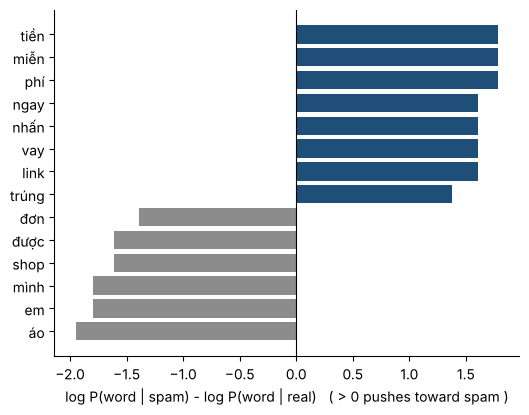

the words with ratio near 0 (no information): ['đã', 'chỉ', 'hôm', 'nay', 'nhận']


In [6]:
log_ratio = pd.Series(nb_text.feature_log_prob_[1] - nb_text.feature_log_prob_[0], index=vocab).sort_values()
pick = pd.concat([log_ratio.head(6), log_ratio.tail(8)])
plt.figure(figsize=(6, 4.5))
plt.barh(pick.index, pick.values, color=[GRAY if v < 0 else BLUE for v in pick.values])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("log P(word | spam) - log P(word | real)   ( > 0 pushes toward spam )")
plt.show()
print("the words with ratio near 0 (no information):", list(log_ratio.abs().sort_values().head(5).index))

**Giải thích từng dòng**

- `nb_text.feature_log_prob_[1] - nb_text.feature_log_prob_[0]`: hiệu log xác suất của nhóm rác trừ nhóm thật cho từng từ = **log của tỉ số khả năng**: dương nghĩa là "từ này hay gặp ở rác hơn".
- `pd.concat([log_ratio.head(6), log_ratio.tail(8)])`: (đã học `concat`) ghép sáu từ nghiêng về "thật" nhất (đầu) và tám từ nghiêng về "rác" nhất (cuối).
- `plt.barh(pick.index, pick.values, color=[...])`: **mới:** `barh` vẽ cột **nằm ngang** (tiện khi tên dài); màu theo dấu: xanh đẩy về rác, xám đẩy về thật.

**Cách đọc**

- **Con số:** các từ "miễn", "phí", "link", "nhấn" có hiệu log từ **+{vn(g['log_ratio'].loc[['miễn', 'phí', 'link', 'nhấn']].min(), 1)}** đến **+{vn(g['log_ratio'].loc[['miễn', 'phí', 'link', 'nhấn']].max(), 1)}** (nằm sát phía phải: đẩy rác mạnh); "shop", "áo" là **{vn(g['log_ratio'].loc[['shop', 'áo']].max(), 1)}** và **{vn(g['log_ratio'].loc['áo'], 1)}** (phía trái: đẩy về tin thật). Hình chỉ vẽ hai đầu; dòng in cuối cho biết các từ **gần số 0** nhất ({', '.join(g['log_ratio'].abs().sort_values().head(5).index)}): hầu như không mang thông tin.
- **Bức tranh:** biểu đồ cột cân đối hai phía, giống một **cán cân**: mỗi từ đặt một quả cân lên hai đĩa, và tin nhắn bị gán nhãn theo đĩa nặng hơn.
- **Ý nghĩa:** đây là **ưu thế đặc biệt** của Naive Bayes: *giải thích được từng từ đóng góp thế nào*, mà không cần công cụ phức tạp.

Núm vặn `alpha` làm gì? Thử bỏ làm trơn (`alpha` rất nhỏ) với một tin có manh mối **lẫn lộn**: "link miễn phí" (của tin rác) cùng "shop ơi cho mình hỏi" (của tin thật):

In [7]:
tricky = "shop ơi cho mình hỏi link miễn phí không"
for a in [1.0, 1e-10]:
    m = MultinomialNB(alpha=a).fit(counts, sms["spam"])
    print(f"alpha = {a:<7}: P(spam) = {m.predict_proba(vec.transform([tricky]))[0, 1]:.4f}")

alpha = 1.0    : P(spam) = 0.0792
alpha = 1e-10  : P(spam) = 0.0000


**Giải thích từng dòng**

- `tricky = "shop ơi cho mình hỏi link miễn phí không"`: tin có hai kiểu manh mối **mâu thuẫn**: "link miễn phí" là dấu hiệu rác; "shop ơi cho mình hỏi" là dấu hiệu thật.
- `for a in [1.0, 1e-10]:`: so làm trơn bình thường (1) với gần như không làm trơn (1e-10, tức 0,0000000001: dùng số rất nhỏ chứ không đúng 0 vì sklearn không cho `alpha = 0`).

**Cách đọc:** với `alpha = 1`, xác suất rác là **0,079**: máy cân nhắc cả hai phía, nghiêng về tin thật nhưng vẫn chừa chỗ cho nghi ngờ. Với `alpha` gần 0 thì xác suất rác thành **0,0000**: tuyệt đối "tin thật". Vì sao? Mỗi từ *chưa từng xuất hiện* ở một nhóm kéo khả năng của nhóm đó về gần 0. Ở nhóm rác có **bốn** từ như vậy (shop, ơi, mình, hỏi) còn ở nhóm thật có **ba** (link, miễn, phí). Nhóm nào dính nhiều "số không" hơn thì bị loại, bất kể các manh mối còn lại. Một quyết định cực đoan chỉ vì *đếm được vài lần*. Làm trơn (`alpha = 1`) là bảo hiểm cho việc đó.

**Mang về chặng 2:** `alpha` là núm làm trơn (+1 là mặc định, giá trị nhỏ thì tin gần như tuyệt đối vào từng lần đếm). Hiệu `feature_log_prob_` giữa các nhóm cho biết **từ nào đẩy tin về phía nào**.

## Chặng 3: Số đo liên tục, `GaussianNB` và các đường chuông

**Câu hỏi:** nếu cột là *số đo liên tục* (độ cồn của rượu, kích thước u...) chứ không phải số đếm từ, ta "đếm" thế nào?

Thay vì đếm tần suất, ta cho **mỗi nhóm một đường chuông** (phân phối chuẩn) mô tả cột đó: có **trung bình** μ và **độ phân tán** σ². *Khả năng* của một giá trị `x` ở nhóm đó chính là **độ cao của đường chuông tại `x`**. Quay lại rượu của anh Tú (C3), xét một cột `flavanoids`.

class_prior_: [0.331 0.398 0.271]
theta_ (mean per class): [2.94 2.03 0.78]
var_   (variance per class): [0.138 0.366 0.097]


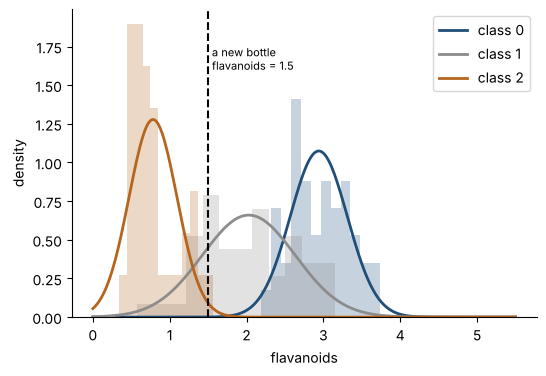

likelihood (bell height at 1.5): [0.001, 0.45, 0.092]
posterior P(class | flavanoids = 1.5): [0.001 0.878 0.121]


In [8]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn.naive_bayes import GaussianNB
wine = load_wine(as_frame=True)
Xw, yw = wine.data, wine.target
Xw_train, Xw_test, yw_train, yw_test = train_test_split(Xw, yw, test_size=0.25, random_state=42, stratify=yw)
gnb1 = GaussianNB().fit(Xw_train[["flavanoids"]], yw_train)
print("class_prior_:", gnb1.class_prior_.round(3))
print("theta_ (mean per class):", gnb1.theta_.ravel().round(2))
print("var_   (variance per class):", gnb1.var_.ravel().round(3))

xs = np.linspace(0, 5.5, 300)
def bell(x, mean, var):
    return np.exp(-(x - mean) ** 2 / (2 * var)) / np.sqrt(2 * np.pi * var)
for cls, color in [(0, BLUE), (1, GRAY), (2, "#B5651D")]:
    plt.hist(Xw_train.loc[yw_train == cls, "flavanoids"], bins=12, density=True, alpha=0.25, color=color)
    plt.plot(xs, bell(xs, gnb1.theta_[cls, 0], gnb1.var_[cls, 0]), color=color, linewidth=2, label=f"class {cls}")
plt.axvline(1.5, color="black", linestyle="--"); plt.text(1.55, 1.6, "a new bottle\nflavanoids = 1.5", fontsize=8)
plt.xlabel("flavanoids"); plt.ylabel("density"); plt.legend(loc="upper right"); plt.show()
x_new = pd.DataFrame({"flavanoids": [1.5]})
print("likelihood (bell height at 1.5):", [round(float(bell(1.5, gnb1.theta_[c, 0], gnb1.var_[c, 0])), 3) for c in range(3)])
print("posterior P(class | flavanoids = 1.5):", gnb1.predict_proba(x_new).round(3)[0])

**Giải thích từng dòng**

- `from sklearn.naive_bayes import GaussianNB`: **mới:** Naive Bayes cho **số liên tục**, mỗi cột mỗi nhóm một đường chuông.
- `gnb1 = GaussianNB().fit(Xw_train[["flavanoids"]], yw_train)`: `fit` chỉ việc tính, **cho mỗi nhóm và mỗi cột**, trung bình và phương sai (độ lệch chuẩn bình phương). Không lặp, không tối ưu: tức thì.
- `gnb1.class_prior_`: xác suất tiên nghiệm của mỗi giống (theo tỉ lệ trong tập học).
- `gnb1.theta_ và gnb1.var_`: **mới:** `theta_` là trung bình, `var_` là phương sai, mỗi hàng một nhóm, mỗi cột một cột đề. Với một cột đề thì mỗi mảng có hình (3, 1); `.ravel()` duỗi thành ba số.
- `def bell(x, mean, var):`: công thức đường chuông: `exp(−(x−μ)² / 2σ²) / √(2πσ²)`. Đây là *độ cao* của chuông tại `x`; không phải xác suất, vì cột liên tục không có "xác suất đúng bằng một giá trị", nhưng đủ để so các nhóm với nhau.
- `plt.hist(..., density=True, alpha=0.25, ...)`: (đã học) biểu đồ cột nền mờ với `density=True` để cùng thang với đường chuông.
- `gnb1.predict_proba(x_new)`: xác suất hậu nghiệm: tiên nghiệm × độ cao chuông, chuẩn hóa để cộng bằng 1.

**Cách đọc**

- **Con số:** `flavanoids` trung bình ở ba giống là **2,94**, **2,03** và **0,78**. Với chai mới có `flavanoids = 1,5`: độ cao chuông ở ba giống là 0,001, 0,450, 0,092; sau khi nhân tiên nghiệm và chuẩn hóa, **P(giống 1) = 0,878**.
- **Bức tranh:** ba chuông xếp từ trái sang phải: giống 2 (nâu) bên trái, **hẹp và cao nhất** (phương sai nhỏ nên các chai giống này rất đồng đều); giống 1 (xám) ở giữa, **rộng và thấp nhất**; giống 0 (xanh) bên phải. Đường kẻ đứt tại 1,5 cắt **chủ yếu chuông xám** và rìa chuông nâu: máy kết luận "giống 1, nhưng giống 2 cũng đáng kể".
- **Ý nghĩa:** `GaussianNB` giả định mỗi cột *trong mỗi nhóm* có dạng **hình chuông**. Ở đây khá ổn; nếu một cột lệch nặng (ví dụ thu nhập), giả định này sai và nên biến đổi cột trước (log, B4).
- **Hồ sơ mô hình `GaussianNB`:** `X` toàn số (cột liên tục); `y` nhãn nhóm; **không chịu `NaN`**; **không cần chuẩn hóa** (mỗi cột có chuông riêng, thang đo không quan trọng: khác k-NN); `fit` chỉ tính trung bình và phương sai; sau `fit` có `theta_`, `var_`, `class_prior_`, `classes_`.

Giờ dùng cả **13 cột** và so với hai mô hình đã học trên cùng cách đo (kiểm định chéo lặp, chỉ trên tập học):

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
race = {
    "GaussianNB (13 cols)": GaussianNB(),
    "k-NN, k=9 (scaled)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "logistic (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
}
race_scores = {name: cross_val_score(m, Xw_train, yw_train, cv=cv) for name, m in race.items()}
print(pd.DataFrame({name: {"CV mean": s.mean(), "CV std": s.std()} for name, s in race_scores.items()}).T.round(3).to_string())

                      CV mean  CV std
GaussianNB (13 cols)    0.963   0.030
k-NN, k=9 (scaled)      0.965   0.029
logistic (scaled)       0.982   0.020


**Giải thích từng dòng**

- `race = {...}`: ba ứng viên. Chú ý `GaussianNB` đứng một mình, **không cần** `StandardScaler`.
- `race_scores = {name: cross_val_score(m, ...) for name, m in race.items()}`: (đã học dict comprehension) 50 điểm cho mỗi ứng viên.

**Cách đọc:** GaussianNB đạt **0,963**, k-NN **0,965**, logistic **0,982**. Cả ba trên 0,96: *một mô hình đếm trung bình và phương sai đã cạnh tranh được với mô hình tối ưu hơn*. Logistic nhỉnh hơn khoảng 0,02; với độ lệch chuẩn khoảng 0,03, đó vẫn là vùng nhiễu.

**Mang về chặng 3:** `GaussianNB` cho mỗi nhóm và mỗi cột một đường chuông; khả năng là độ cao chuông. Không cần chuẩn hóa. Rất nhanh.

## Chặng 4: Chữ "ngây thơ", đúng nhãn nhưng quá tự tin

**Câu hỏi:** giả định "các cột độc lập" có thật không? Và nếu sai thì hậu quả gì?

Với bộ ung thư vú (30 cột, nhiều cột là *cùng một thứ đo theo nhiều cách*: bán kính, chu vi, diện tích của nhân tế bào), các cột **cực kỳ tương quan**. Naive Bayes coi mỗi cột là một nhân chứng độc lập; nhưng ở đây nhiều "nhân chứng" thật ra là *một người nói đi nói lại*. Kết quả: nó **cộng dồn** cùng một bằng chứng nhiều lần và trở nên **quá tự tin**.

column pairs with |correlation| > 0.9: 21 of 435


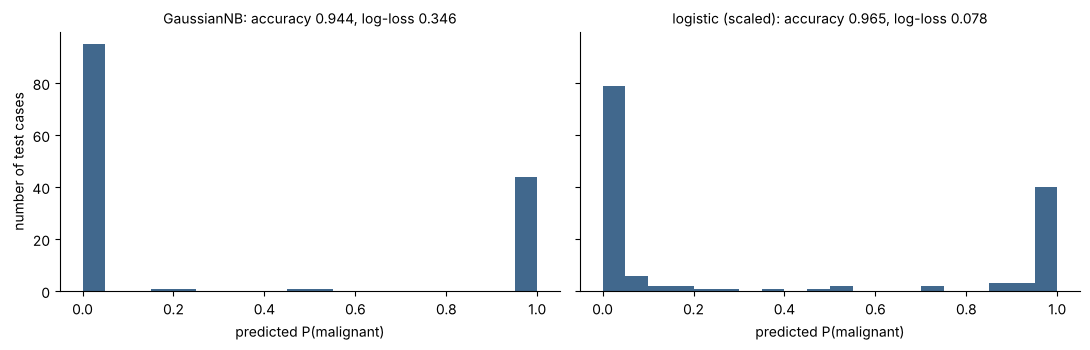

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import log_loss, accuracy_score
bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, 1 - bc.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.25, random_state=42, stratify=yb)
corr = Xb_train.corr().abs().values
n_pairs_high = int(((np.triu(corr, k=1)) > 0.9).sum())
print(f"column pairs with |correlation| > 0.9: {n_pairs_high} of {30 * 29 // 2}")
fits = {"GaussianNB": GaussianNB().fit(Xb_train, yb_train),
        "logistic (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xb_train, yb_train)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, m) in zip(axes, fits.items()):
    p = m.predict_proba(Xb_test)[:, 1]
    ax.hist(p, bins=20, range=(0, 1), color=BLUE, alpha=0.85)
    ax.set_title(f"{name}: accuracy {accuracy_score(yb_test, m.predict(Xb_test)):.3f}, log-loss {log_loss(yb_test, p):.3f}", fontsize=10)
    ax.set_xlabel("predicted P(malignant)")
axes[0].set_ylabel("number of test cases")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `corr = Xb_train.corr().abs().values`: (đã học `.corr()` ở A3) bảng tương quan 30×30, lấy trị tuyệt đối rồi chuyển thành mảng numpy.
- `np.triu(corr, k=1)`: **mới:** `np.triu` giữ **nửa tam giác trên** của bảng (bỏ đường chéo nhờ `k=1`), để mỗi cặp cột chỉ đếm một lần, không đếm cặp (a, b) và (b, a) hai lần.
- `n_pairs_high = int(((...) > 0.9).sum())`: đếm số cặp cột có tương quan trên 0,9: tức gần như cùng một thông tin.
- `fits = {...}`: hai mô hình học trên cùng dữ liệu.
- `ax.hist(p, bins=20, range=(0, 1), ...)`: biểu đồ cột phân bố **xác suất ác** mà mô hình đưa ra cho 143 ca thi, chia thành 20 khoảng từ 0 đến 1.
- `log_loss(yb_test, p)`: (đã học ở C1) phạt nặng tự tin mà sai.

In [11]:
sure_stats = {}
for name, m in fits.items():
    p = m.predict_proba(Xb_test)[:, 1]
    sure = (p < 0.01) | (p > 0.99)
    wrong_when_sure = int((m.predict(Xb_test)[sure] != yb_test.values[sure]).sum())
    sure_stats[name] = (int(sure.sum()), wrong_when_sure)
    print(f"{name:18s}: says 'at least 99% sure' on {sure.sum()} of {len(p)} cases; wrong among those: {wrong_when_sure}")

GaussianNB        : says 'at least 99% sure' on 137 of 143 cases; wrong among those: 5
logistic (scaled) : says 'at least 99% sure' on 101 of 143 cases; wrong among those: 0


**Giải thích từng dòng**

- `sure = (p < 0.01) | (p > 0.99)`: mặt nạ Đúng/Sai: ca nào mô hình **tự tin tuyệt đối** (xác suất ác dưới 1% hoặc trên 99%). Dấu `|` là "hoặc" (đã học `&` là "và").
- `(m.predict(Xb_test)[sure] != yb_test.values[sure]).sum()`: trong các ca mô hình tự tin đó, đếm số ca mô hình **đoán sai**.

**Cách đọc**

- **Con số:** có **21** trên 435 cặp cột tương quan hơn 0,9. Độ đúng của hai mô hình khá gần (Naive Bayes 0,944, logistic 0,965), nhưng **log-loss** khác xa: Naive Bayes 0,346 so với logistic 0,078, gấp nhiều lần.
- **Con số về sự tự tin:** Naive Bayes nói "chắc ít nhất 99%" trên **137** trong 143 ca, và **sai 5** ca trong số đó; logistic chỉ nói câu đó với 101 ca và sai 0. Lời nói "chắc 99%" của Naive Bayes **không đáng tin 99%**.
- **Bức tranh:** cả hai biểu đồ đều dồn về hai mép 0 và 1 vì bài này khá dễ. Nhưng biểu đồ trái (Naive Bayes) *dồn cực đoan hơn*: gần như không có ca nào ở khoảng giữa, hai cột ở mép cao vút; biểu đồ phải (logistic) còn **trải một ít** ở khoảng giữa, và nhiều ca dừng ở "khá chắc" chứ không phải "tuyệt đối". Cả hai đều xếp hạng rất tốt (AUC cao, C2); khác nhau ở chỗ *lời hứa về mức chắc chắn* của logistic đáng tin hơn.
- **Ý nghĩa:** khi nhiều cột nói cùng một điều, Naive Bayes **nhân chồng bằng chứng** và đẩy xác suất về hai mép. Mỗi lần nó nói "chắc 99%" và sai, log-loss bị phạt nặng. Hệ quả thực tế: **dùng Naive Bayes để xếp hạng hoặc đoán nhãn thì được; dùng nó để *đọc xác suất* thì phải cẩn thận** (muốn xác suất đáng tin, dùng hiệu chỉnh xác suất: `CalibratedClassifierCV`, sẽ gặp ở phần D).

**Mang về chặng 4:** giả định độc lập bị vi phạm khi các cột tương quan; mô hình vẫn đoán nhãn khá tốt nhưng **quá tự tin**. Nhìn **log-loss** và biểu đồ phân bố xác suất, không chỉ độ đúng.

## Chặng 5: Nhìn chữ số bằng mắt của Naive Bayes

**Câu hỏi:** Naive Bayes "nhìn thấy" gì khi học chữ số viết tay?

Bộ `load_digits` có 1797 ảnh chữ số viết tay cỡ **8×8 điểm ảnh** (mỗi ảnh là 64 số, độ đậm từ 0 đến 16). Với `MultinomialNB`, mỗi điểm ảnh là một "từ" và độ đậm là "số lần xuất hiện": giống hệt bài tin nhắn. Mô hình học: *điểm ảnh nào hay đậm khi chữ số là 0, là 1, ...* Sau `fit`, `feature_log_prob_` giữ đúng điều đó, và ta có thể **vẽ nó thành ảnh**.

X shape: (1797, 64) | pixel values from 0.0 to 16.0 | feature_log_prob_ shape: (10, 64)


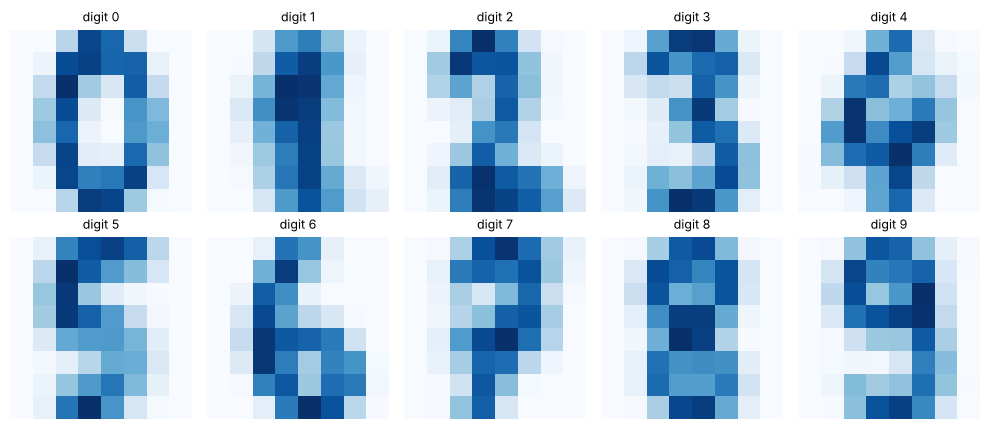

test accuracy, MultinomialNB: 0.882


In [12]:
from sklearn.datasets import load_digits
digits = load_digits()
Xd, yd = digits.data, digits.target
Xd_train, Xd_test, yd_train, yd_test = train_test_split(Xd, yd, test_size=0.25, random_state=42, stratify=yd)
mnb = MultinomialNB(alpha=1.0).fit(Xd_train, yd_train)
print("X shape:", Xd.shape, "| pixel values from", Xd.min(), "to", Xd.max(), "| feature_log_prob_ shape:", mnb.feature_log_prob_.shape)
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for digit, ax in enumerate(axes.ravel()):
    ax.imshow(np.exp(mnb.feature_log_prob_[digit]).reshape(8, 8), cmap="Blues")
    ax.set_title(f"digit {digit}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()
print("test accuracy, MultinomialNB:", round(mnb.score(Xd_test, yd_test), 3))

**Giải thích từng dòng**

- `from sklearn.datasets import load_digits`: bộ chữ số viết tay 8×8: `digits.data` là bảng (1797, 64), `digits.target` là chữ số thật (0 đến 9).
- `MultinomialNB(alpha=1.0).fit(Xd_train, yd_train)`: dùng nguyên máy của chặng 2: độ đậm (0 đến 16) đóng vai số lần đếm. Cột không âm nên hợp với `MultinomialNB`.
- `np.exp(mnb.feature_log_prob_[digit]).reshape(8, 8)`: `feature_log_prob_[digit]` là log xác suất 64 điểm ảnh của chữ số đó; `np.exp` đưa về xác suất; `.reshape(8, 8)` xếp lại thành ảnh vuông 8×8 để vẽ.
- `ax.imshow(..., cmap="Blues")`: `imshow` vẽ mảng 2 chiều thành **ảnh**; `cmap="Blues"` là thang màu xanh: ô đậm là điểm ảnh hay sáng ở chữ số đó.
- `for digit, ax in enumerate(axes.ravel()):`: (đã học `enumerate`) `axes.ravel()` duỗi lưới 2×5 khung thành dãy 10 khung; mỗi chữ số một khung. `ax.axis("off")` ẩn trục.

**Cách đọc**

- **Con số:** độ đúng trên tập thi **0,882**: mười lớp, đoán bừa chỉ khoảng 0,10.
- **Bức tranh:** mỗi ô là "ảnh chân dung" của một chữ số theo Naive Bayes: số 0 sáng thành vòng tròn, số 1 sáng thành một sọc dọc, số 7 sáng ở hàng trên và nét chéo. Chúng giống **ảnh trung bình mờ** của mỗi chữ số. Khi nhận một ảnh mới, Naive Bayes hỏi: *"điểm ảnh nào sáng ở ảnh này, và với từng chữ số thì các điểm ảnh ấy có hay sáng không?"* rồi cộng bằng chứng.
- **Ý nghĩa:** đây là thứ mà mô hình học được; đọc được bằng mắt. Nhưng nó coi 64 điểm ảnh là **độc lập**, trong khi hai điểm ảnh kề nhau thì gần như luôn cùng sáng hoặc cùng tối. Nó thiếu hẳn thông tin *"nét liền"* và đây là lý do độ đúng bị chặn ở khoảng 0,88.

So với hai mô hình khác trên cùng chia tập:

In [13]:
rivals = {
    "MultinomialNB": MultinomialNB(),
    "GaussianNB": GaussianNB(),
    "logistic (scaled)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
}
for name, m in rivals.items():
    print(f"{name:20s} test accuracy = {m.fit(Xd_train, yd_train).score(Xd_test, yd_test):.3f}")

MultinomialNB        test accuracy = 0.882
GaussianNB           test accuracy = 0.829
logistic (scaled)    test accuracy = 0.978


**Giải thích từng dòng**

- `rivals = {...}`: ba ứng viên: hai kiểu Naive Bayes và logistic.
- `m.fit(Xd_train, yd_train).score(Xd_test, yd_test)`: (đã học) học rồi chấm trên tập thi; một lần chia nên chỉ để minh họa.

**Cách đọc:** `MultinomialNB` 0,882, `GaussianNB` 0,829, logistic **0,978**. Khoảng cách này lớn (cỡ 10 điểm phần trăm) nên không thể gọi là nhiễu. Đây là **cái giá của giả định ngây thơ** khi các cột thật sự phụ thuộc nhau mạnh. Logistic học được *trọng số riêng cho từng điểm ảnh sau khi đã tính đến các điểm ảnh khác*; Naive Bayes thì không.

**Mang về chặng 5:** `MultinomialNB` hợp với **số đếm không âm**; `feature_log_prob_` là thứ ta có thể vẽ ra đọc. Khi các cột phụ thuộc mạnh (điểm ảnh kề nhau) và có đủ dữ liệu, các mô hình biết tính đến sự phụ thuộc (logistic) hơn hẳn.

## Chặng 6: Khi nào Naive Bayes đáng dùng

**Câu hỏi:** nếu nó "ngây thơ" thế, sao vẫn dùng?

Một câu trả lời kinh điển: **khi dữ liệu rất ít, Naive Bayes học nhanh hơn**. Nó chỉ cần ước lượng từng cột *riêng lẻ* (trung bình, tần suất), trong khi logistic phải ước lượng cả tổ hợp các cột. Ta kiểm chứng bằng **đường cong học** (learning curve): cho mỗi mô hình học trên 20, 50, 100, ... mẫu rồi đo trên tập thi cố định.

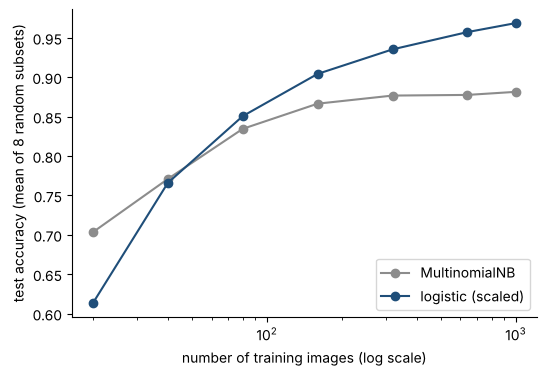

      MultinomialNB  logistic (scaled)
20            0.703              0.613
40            0.771              0.766
80            0.834              0.851
160           0.866              0.904
320           0.877              0.935
640           0.878              0.957
1000          0.881              0.969


In [14]:
sizes = [20, 40, 80, 160, 320, 640, 1000]
rng = np.random.default_rng(0)
curves = {"MultinomialNB": [], "logistic (scaled)": []}
for n in sizes:
    acc = {k: [] for k in curves}
    for rep in range(8):
        pick = rng.choice(len(Xd_train), size=n, replace=False)
        for name, m in [("MultinomialNB", MultinomialNB()), ("logistic (scaled)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)))]:
            acc[name].append(m.fit(Xd_train[pick], yd_train[pick]).score(Xd_test, yd_test))
    for name in curves:
        curves[name].append(np.mean(acc[name]))
for name, color in [("MultinomialNB", GRAY), ("logistic (scaled)", BLUE)]:
    plt.plot(sizes, curves[name], "o-", color=color, label=name)
plt.xscale("log"); plt.xlabel("number of training images (log scale)"); plt.ylabel("test accuracy (mean of 8 random subsets)")
plt.legend(loc="lower right"); plt.show()
print(pd.DataFrame(curves, index=sizes).round(3).to_string())

**Giải thích từng dòng**

- `sizes = [20, 40, 80, 160, 320, 640, 1000]`: các cỡ tập học thử: từ rất ít đến gần hết.
- `pick = rng.choice(len(Xd_train), size=n, replace=False)`: bốc ngẫu nhiên `n` ảnh *không hoàn lại* (`replace=False`) từ tập học để làm tập học nhỏ.
- `Xd_train[pick], yd_train[pick]`: lấy các dòng theo vị trí đã bốc (mảng numpy nên lọc thẳng bằng danh sách vị trí).
- `for rep in range(8):`: lặp tám lần với tám tập con khác nhau rồi lấy trung bình, để đường bớt gập ghềnh. (`rep` không được dùng trong thân vòng lặp; chỉ là bộ đếm.)

**Cách đọc**

- **Con số:** với 20 ảnh học, Naive Bayes đạt **0,703**, logistic **0,613**. Với 1000 ảnh: Naive Bayes **0,881**, logistic **0,969**.
- **Bức tranh:** hai đường cùng đi lên khi có thêm dữ liệu; Naive Bayes **leo nhanh lúc đầu rồi chững lại** sớm, trong khi logistic **leo chậm hơn nhưng không chững** và vượt lên. Hai đường **giao nhau quanh 40 đến 80 ảnh**: từ đó trở đi logistic dẫn trước và khoảng cách giãn rộng ra. Đó là điểm "đủ dữ liệu để mô hình biết tính phụ thuộc thắng".
- **Ý nghĩa:** Naive Bayes có **thiên lệch cao nhưng phương sai thấp** (giả định sai nhưng ổn định); logistic ngược lại. Ít dữ liệu thì ổn định thắng, nhiều dữ liệu thì chính xác thắng. Đây là nguyên lý chung (A1, B5), không riêng gì Naive Bayes.

## Phán quyết và bài học nghề

**Phán quyết cho chị Lan.** Với **24 tin**, Naive Bayes là lựa chọn hợp lý: nhanh, ít dữ liệu, và *giải thích được* từng từ đóng góp thế nào (chặng 2). Dùng `MultinomialNB` + `CountVectorizer`; **hứa với chị đừng đọc xác suất như thật**; chỉ dùng để gợi ý, tin có điểm rác ở khoảng giữa cần chị xem. Khi tích lũy vài nghìn tin, thử logistic so lại.

**Bài học nghề.**

1. **Naive Bayes = tiên nghiệm × tích khả năng từng cột**, nhờ giả định cột độc lập khi đã biết nhóm.
2. **Có ba bản:** `MultinomialNB` (số đếm: chữ, ảnh), `GaussianNB` (số liên tục), `BernoulliNB` (có/không).
3. **`fit` chỉ đếm hoặc tính trung bình**: tức thì, không lặp. Không cần chuẩn hóa (`GaussianNB`).
4. **`alpha` làm trơn** để từ chưa gặp không phá cả phép tính.
5. **Hay đoán đúng nhãn nhưng quá tự tin về xác suất**: nhìn log-loss, đừng chỉ nhìn độ đúng.
6. **Hợp khi ít dữ liệu, chữ, cần mốc nhanh**; thua mô hình biết xử lý phụ thuộc giữa các cột khi có nhiều dữ liệu.

**Một điều thành thật:** 24 tin của buổi này là *ví dụ đồ chơi tự soạn*. Con số 0,99 ở chặng 1 nói về cách tính, không nói về chất lượng bộ lọc thật. Bộ lọc thật cần hàng nghìn tin và đo bằng kiểm định như C2.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Naive Bayes = tiên nghiệm × khả năng từng cột (giả định cột độc lập khi biết nhóm); dùng log để cộng. |
| 2 | `MultinomialNB` cho số đếm, `alpha` làm trơn; `feature_log_prob_` cho biết cột nào đẩy về nhóm nào. |
| 3 | `GaussianNB` cho số liên tục: mỗi nhóm mỗi cột một đường chuông; không cần chuẩn hóa. |
| 4 | Các cột tương quan khiến xác suất quá tự tin: log-loss cao dù độ đúng ổn. |
| 5 | Ảnh chữ số: Naive Bayes coi điểm ảnh độc lập, thua logistic khoảng 10 điểm phần trăm. |
| 6 | Ít dữ liệu thì Naive Bayes ổn định; nhiều dữ liệu thì mô hình biết tính phụ thuộc thắng. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Tỉ lệ mỗi nhóm trước khi nhìn bằng chứng | xác suất tiên nghiệm (prior) | `class_log_prior_`, `class_prior_` |
| Mức hay gặp của một từ trong một nhóm | khả năng (likelihood) | `feature_log_prob_` |
| Xác suất sau khi cộng mọi bằng chứng | xác suất hậu nghiệm | `predict_proba` |
| Đổi chữ thành bảng đếm từ | vector hóa đếm từ | `CountVectorizer` |
| Cộng thêm số vào mọi lần đếm cho khỏi bằng 0 | làm trơn Laplace | `alpha=` |
| Mỗi nhóm mỗi cột một đường chuông | Naive Bayes Gauss | `GaussianNB`, `theta_`, `var_` |
| Cột nói cùng một điều bị đếm nhiều lần | vi phạm giả định độc lập | tương quan cao |
| Đường thể hiện điểm khi tăng dữ liệu học | đường cong học | đo theo cỡ tập học |

**Thử thách tự làm**

1. Ở chặng 2, thêm tin mới "giảm giá sốc cho khách hàng" và dự đoán. Thay `alpha` thành 0,1 và 10. Xác suất rác thay đổi thế nào, vì sao?
2. Ở chặng 4, giữ lại chỉ **ba cột** ít tương quan với nhau (ví dụ chọn bằng bảng tương quan) cho Naive Bayes. Độ đúng và log-loss thay đổi ra sao? Điều đó xác nhận điều gì?
3. Kể chuyện với dữ liệu khác: dùng `load_iris` cho `GaussianNB`. Vẽ đường chuông của `petal width` theo ba loài, so độ đúng với k-NN và logistic.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Viết được công thức Bayes (tiên nghiệm × khả năng) và giải thích bằng ví dụ đếm.
- [ ] Giải thích vì sao dùng logarit và vì sao cần làm trơn.
- [ ] Chọn đúng `MultinomialNB`, `GaussianNB` theo loại cột.
- [ ] Đọc `feature_log_prob_` hoặc `theta_` và `var_`.
- [ ] Giải thích vì sao Naive Bayes quá tự tin khi các cột tương quan.
- [ ] Nêu khi nào nên dùng và khi nào nên thôi.

## Phần thưởng (Tip pro): `BernoulliNB`, `CategoricalNB` và `partial_fit` cho dữ liệu khổng lồ


Hai họ hàng nữa của Naive Bayes: **`BernoulliNB`** cho cột **có/không** (từ *có xuất hiện* trong tin hay không, bỏ qua số lần) và **`CategoricalNB`** cho cột **chữ/nhóm** đã mã hóa thành số nguyên (màu, loại). Điểm mạnh ít người biết: vì `fit` chỉ **cộng dồn số đếm**, các máy Naive Bayes có **`partial_fit`**: học **từng mẻ dữ liệu** mà không cần giữ lại cả kho. Ta đưa mẻ đầu, rồi mẻ sau, và mô hình cộng dồn tiếp, hợp với dữ liệu quá lớn để nạp vào bộ nhớ một lần:

In [15]:
inc = MultinomialNB()
for start in range(0, len(Xd_train), 300):
    batch = slice(start, start + 300)
    inc.partial_fit(Xd_train[batch], yd_train[batch], classes=np.arange(10))
print("incremental (batches of 300) accuracy:", round(inc.score(Xd_test, yd_test), 3), "| one-shot fit:", round(mnb.score(Xd_test, yd_test), 3))

incremental (batches of 300) accuracy: 0.882 | one-shot fit: 0.882


**Giải thích từng dòng**

- `inc.partial_fit(X_batch, y_batch, classes=np.arange(10))`: **mới:** `partial_fit` học **thêm** từ một mẻ mà không quên mẻ trước. Lần gọi đầu bắt buộc khai báo **danh sách mọi nhóm** (`classes`), vì mẻ đầu có thể chưa thấy hết các nhóm.
- `batch = slice(start, start + 300)`: `slice(a, b)` là "lát cắt" từ dòng `a` đến `b` dùng để lấy từng mẻ 300 dòng.